# Gas source estimation: basis for adaptive loss weights

Known geometry and wind, with concentration measurements from a saved filament scenario.
The existing `UncertaintyBasedGasSourceEstimator` handles training, LLLA selection,
and accumulated measurements. This notebook contains only experiment setup and plots.

Loss weights are still fixed here; adaptive weighting is the next step.
The true source is used only for evaluation. Measurement order does not represent
an obstacle-aware robot path.


In [40]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.interpolate import NearestNDInterpolator

root = Path.cwd()
if not (root / "source_estimation_pinn").exists():
    root = root.parent
sys.path.insert(0, str(root))

from source_estimation_pinn.environment import OccupancyGrid, WindField
from source_estimation_pinn.estimation import (
    GasSourceConfig,
    GasSourceEstimator,
    # UncertaintyBasedGasSourceEstimator,
)
from source_estimation_pinn.measurements import GasSampleSet


In [41]:
scenario_dir = root / "data/example_labyrinth/scenario_source_1.5_2_seed_7"
metadata = json.loads((scenario_dir / "metadata.json").read_text())
occupancy = OccupancyGrid.from_occupancy_file(scenario_dir / metadata["occupancy"])
wind = WindField.from_csv(scenario_dir / metadata["wind"])
reference = GasSampleSet.from_csv(scenario_dir / metadata["files"]["gas"])
sensor_oracle = NearestNDInterpolator(reference.positions, reference.concentrations)
candidate_points = occupancy.free_points
true_source = np.asarray(metadata["source"]["position"], dtype=float)
effective_diffusivity = (metadata["diffusivity"]
                        + 0.5 * metadata["diffusion_speed_std"] ** 2 * metadata["dt"])

# Snap the original coverage route to distinct free candidate cells.
route_targets = np.vstack((
    np.column_stack((np.linspace(4, 6, 6), np.full(6, 1.5))),
    np.column_stack((np.full(6, 5.0), np.linspace(0.5, 2.5, 6))),
))

print(len(reference.concentrations))
n_measurements = 50
indices = np.random.choice(len(reference.concentrations), size=n_measurements, replace=False)
meas_positions = reference.positions[indices]
meas_concentrations = reference.concentrations[indices]
initial_samples = GasSampleSet(meas_positions, meas_concentrations)
print(f"Initial measurements: {len(meas_positions)}")

4850
Initial measurements: 50


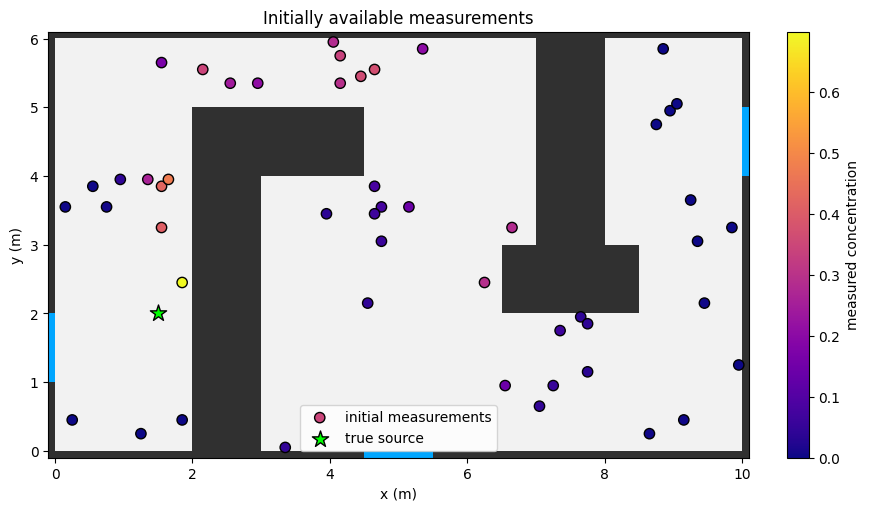

In [42]:
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
occupancy.plot(ax=ax, title="Initially available measurements")
if ax.get_legend() is not None:
    ax.get_legend().remove()
measurements = ax.scatter(
    *initial_samples.positions.T, c=initial_samples.concentrations,
    cmap="plasma", s=55, edgecolor="black", label="initial measurements", zorder=4,
)
ax.scatter(*true_source, marker="*", s=150, color="lime", edgecolor="black",
           label="true source", zorder=5, clip_on=False)
fig.colorbar(measurements, ax=ax, label="measured concentration")
ax.legend(loc="best")
plt.show()


In [43]:
config = GasSourceConfig(
    concentration_hidden_layers=3,
    concentration_hidden_dim=32,
    source_hidden_layers=3,
    source_hidden_dim=16,
    diffusion_constant=effective_diffusivity,
    dynamic_weights=True,
    lambda_sparse=1e-4,
    lambda_nonfree=1e-2,
    last_layer_prior_precision=1e-6,
    learning_rate=1e-3,
)
model_seed = 5
initial_training_steps = 15000
n_collocation_points = 1500

torch.manual_seed(model_seed)
localizer = GasSourceEstimator(occupancy, wind, config)

history = localizer.fit(initial_samples, initial_training_steps, n_collocation_points)

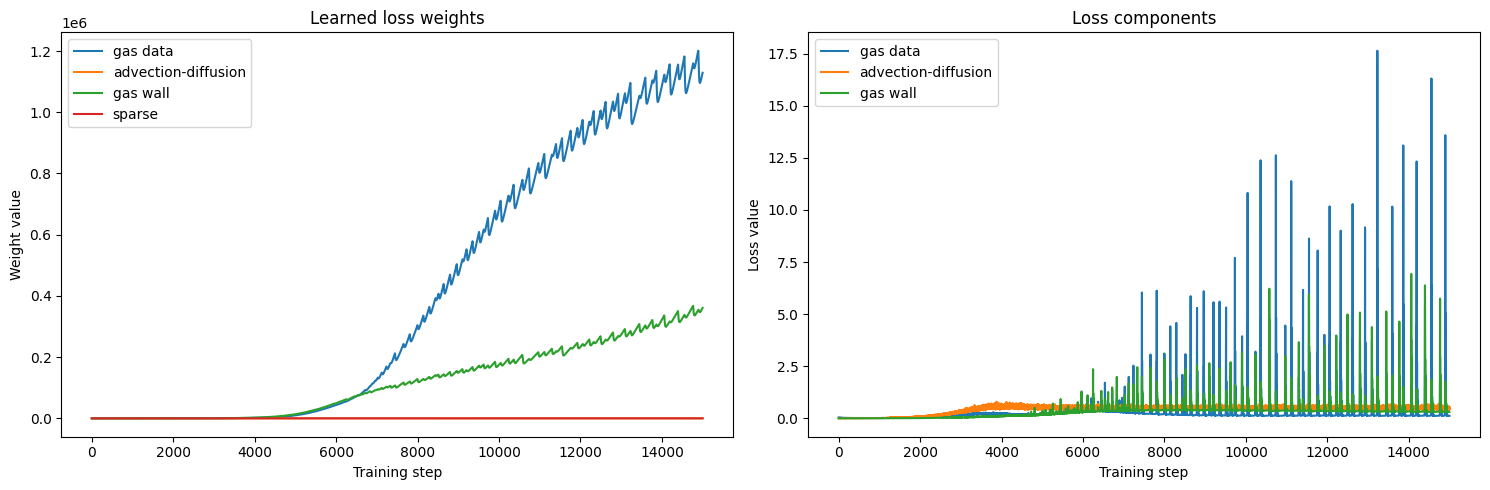

In [44]:
weights = history.weights
losses = history.losses

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.plot(weights["gas_data"], label="gas data")
plt.plot(weights["ad"], label="advection-diffusion")
plt.plot(weights["gas_wall"], label="gas wall")
plt.plot(weights["sparse"], label="sparse")
plt.title("Learned loss weights")
plt.xlabel("Training step")
plt.ylabel("Weight value")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(losses["gas_data"], label="gas data")
plt.plot(losses["ad"], label="advection-diffusion")
plt.plot(losses["gas_wall"], label="gas wall")
plt.title("Loss components")
plt.xlabel("Training step")
plt.ylabel("Loss value")
plt.legend()
plt.tight_layout()

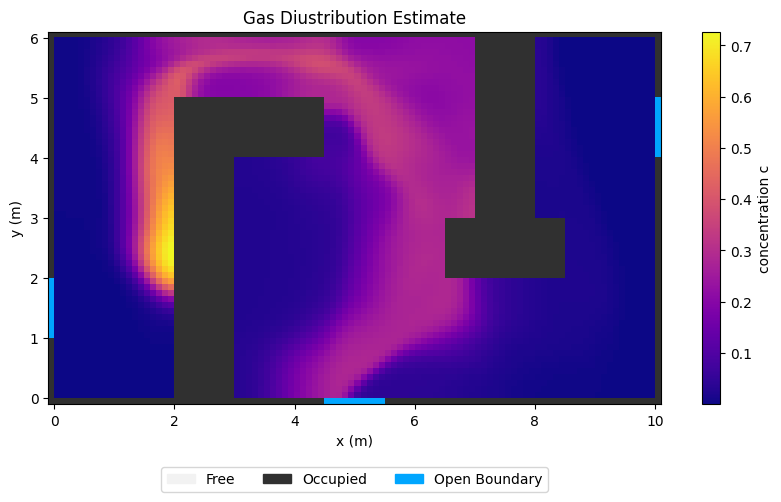

In [45]:
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
occupancy.plot(ax=ax, title="Gas Diustribution Estimate")

values = localizer.predict_concentration(candidate_points)
label = "concentration c"
field = np.full(occupancy.free_mask.shape, np.nan)
field[occupancy.free_mask] = np.asarray(values).reshape(-1)
extent = [occupancy.lower_bound[0], occupancy.upper_bound[0],
          occupancy.lower_bound[1], occupancy.upper_bound[1]]
image = ax.imshow(field, origin="lower", extent=extent,
                  cmap="plasma", interpolation="nearest", zorder=2)
fig.colorbar(image, ax=ax, label=label)

plt.show()

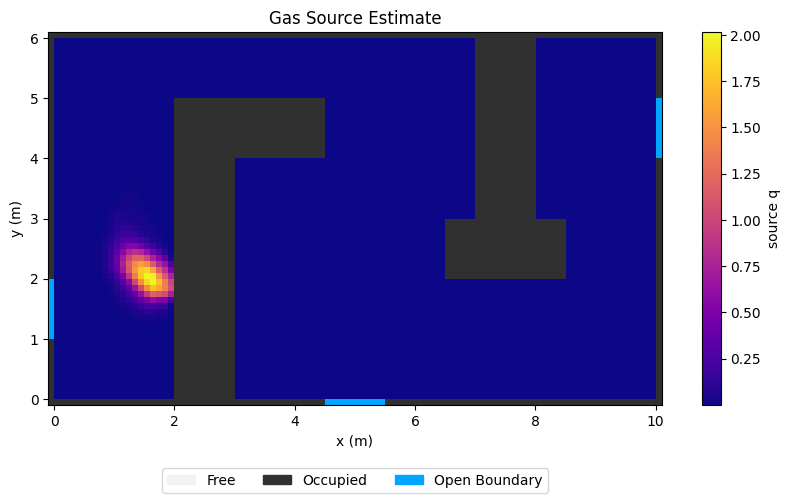

In [46]:
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
occupancy.plot(ax=ax, title="Gas Source Estimate")

values = localizer.predict_source(candidate_points)
label = "source q"
field = np.full(occupancy.free_mask.shape, np.nan)
field[occupancy.free_mask] = np.asarray(values).reshape(-1)
extent = [occupancy.lower_bound[0], occupancy.upper_bound[0],
          occupancy.lower_bound[1], occupancy.upper_bound[1]]
image = ax.imshow(field, origin="lower", extent=extent,
                  cmap="plasma", interpolation="nearest", zorder=2)
fig.colorbar(image, ax=ax, label=label)

plt.show()

## Diagnose und Vergleich: feste vs. adaptive Gewichte

Die bisherigen `history.losses` enthalten **gewichtete** Beiträge. Wir teilen durch
 die protokollierten Gewichte, um die tatsächlichen Residualfehler zu sehen.

Die Vergleichszelle trainiert **zwei neue Modelle** mit den oben eingestellten
Trainingsschritten: gleiche bereits ausgewählte Messungen, identische anfängliche
Netzparameter und identische zufällige Kollokationsfolgen. Nur `dynamic_weights`
unterscheidet sich. Alle anderen Gewichte bleiben wie in `config` eingestellt.

Der Gesamt-Loss ist wegen der zusätzlichen Log-Terme kein gemeinsamer Qualitätsmaßstab.
Wir vergleichen deshalb Rohfehler und Quellschätzungen. Die Quell-Ground-Truth dient
nur zur Evaluation; ihr Feld ist die auf freie Zellen normierte Gauß-Quelle aus den
Szenario-Metadaten. W1 wird hier gegen die **punktförmige Quellposition** berechnet.


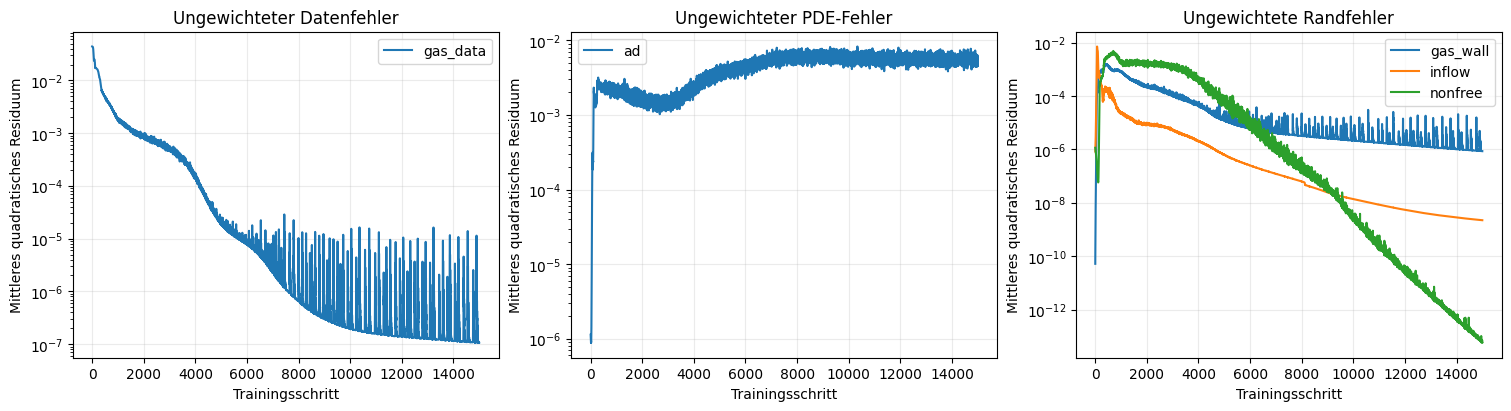

In [47]:
def unweighted_losses(run_history):
    result = {}
    for name, values in run_history.losses.items():
        if name == "total":
            continue
        weights = np.asarray(run_history.weights[name])
        result[name] = np.divide(
            values, weights, out=np.full_like(values, np.nan, dtype=float),
            where=weights > 0,
        )
    return result

raw_losses = unweighted_losses(history)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, names, title in zip(
    axes, [("gas_data",), ("ad",), ("gas_wall", "inflow", "nonfree")],
    ["Ungewichteter Datenfehler", "Ungewichteter PDE-Fehler", "Ungewichtete Randfehler"],
):
    for name in names:
        ax.semilogy(raw_losses[name], label=name)
    ax.set(title=title, xlabel="Trainingsschritt", ylabel="Mittleres quadratisches Residuum")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

In [48]:
from dataclasses import replace
import pandas as pd

cell_area = occupancy.resolution ** 2
reference_q = np.exp(
    -np.sum((candidate_points - true_source) ** 2, axis=1)
    / (2 * metadata["source"]["sigma"] ** 2)
)
reference_q /= cell_area * reference_q.sum()
source_distances = np.linalg.norm(candidate_points - true_source, axis=1)
evaluate_every = max(1, initial_training_steps // 100)


def evaluate_source(estimator, step):
    q = np.asarray(estimator.predict_source(candidate_points)).reshape(-1)
    mass = float(cell_area * q.sum())
    normalized_q = q / mass
    return {
        "step": step,
        "position_error_m": float(source_distances[np.argmax(q)]),
        "point_w1_m": float(cell_area * np.sum(normalized_q * source_distances)),
        "normalized_l2": float(np.sqrt(cell_area * np.sum((normalized_q - reference_q) ** 2))),
        "source_mass": mass,
    }


comparison_runs = {}
devices = list(range(torch.cuda.device_count())) if torch.cuda.is_available() else []
with torch.random.fork_rng(devices=devices):
    torch.manual_seed(model_seed)
    # Match the upper run: save the training RNG after ONE model construction.
    adaptive_estimator = GasSourceEstimator(occupancy, wind, replace(config, dynamic_weights=True))
    training_rng = torch.get_rng_state().clone()
    training_cuda_rng = torch.cuda.get_rng_state_all() if devices else None
    static_estimator = GasSourceEstimator(occupancy, wind, replace(config, dynamic_weights=False))
    static_estimator.model.load_state_dict(adaptive_estimator.model.state_dict())
    estimators = {"Static": static_estimator, "Adaptive": adaptive_estimator}

    for label, estimator in estimators.items():
        torch.set_rng_state(training_rng)
        if training_cuda_rng is not None:
            torch.cuda.set_rng_state_all(training_cuda_rng)
        progress = [evaluate_source(estimator, 0)]

        def record_source(step, losses):
            completed = step + 1
            if completed % evaluate_every == 0 or completed == initial_training_steps:
                progress.append(evaluate_source(estimator, completed))

        print(f"{label}: {initial_training_steps} Trainingsschritte", flush=True)
        run_history = estimator.fit(
            initial_samples, steps=initial_training_steps,
            n_collocation_points=n_collocation_points, callback=record_source,
        )
        comparison_runs[label] = {
            "estimator": estimator, "history": run_history,
            "progress": pd.DataFrame(progress),
        }
        print(f"  Finaler Positionsfehler: {progress[-1]['position_error_m']:.3f} m", flush=True)

Static: 15000 Trainingsschritte


  Finaler Positionsfehler: 0.212 m
Adaptive: 15000 Trainingsschritte
  Finaler Positionsfehler: 0.158 m


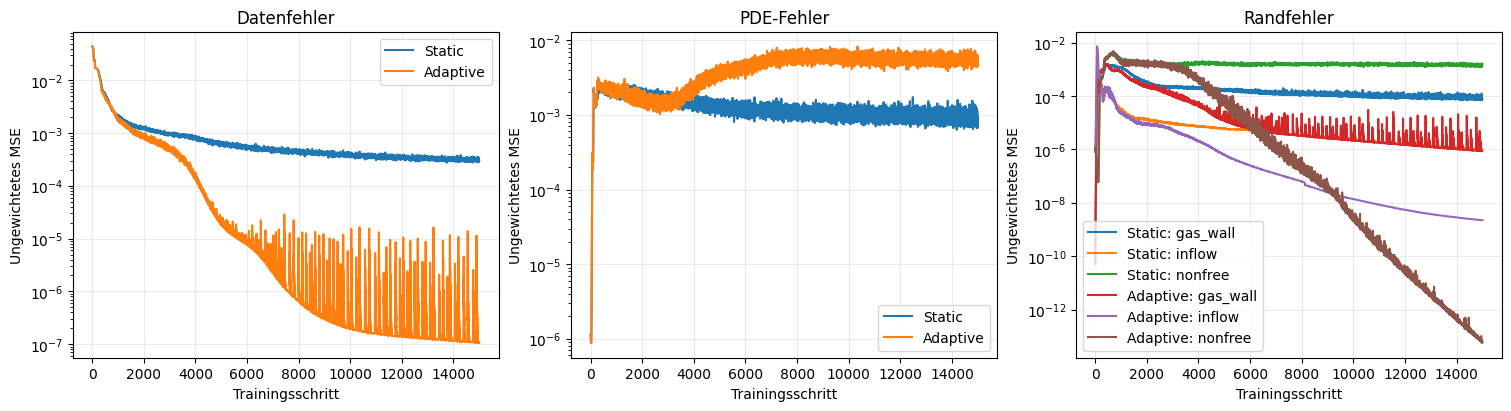

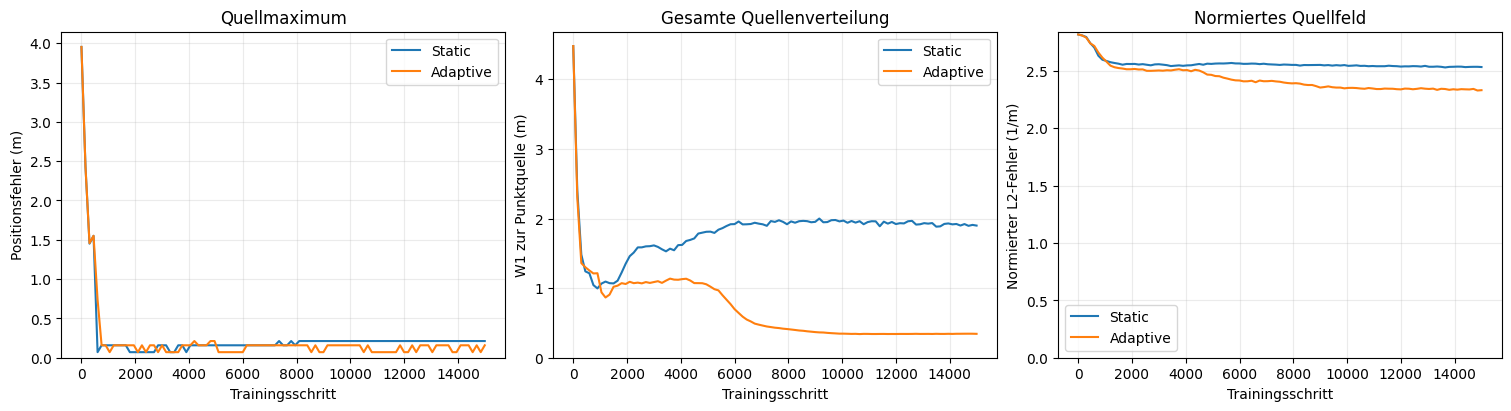

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for label, run in comparison_runs.items():
    raw = unweighted_losses(run["history"])
    axes[0].semilogy(raw["gas_data"], label=label)
    axes[1].semilogy(raw["ad"], label=label)
    for name in ("gas_wall", "inflow", "nonfree"):
        axes[2].semilogy(raw[name], label=f"{label}: {name}")
for ax, title in zip(axes, ["Datenfehler", "PDE-Fehler", "Randfehler"]):
    ax.set(title=title, xlabel="Trainingsschritt", ylabel="Ungewichtetes MSE")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for label, run in comparison_runs.items():
    progress = run["progress"]
    for ax, metric in zip(axes, ["position_error_m", "point_w1_m", "normalized_l2"]):
        ax.plot(progress["step"], progress[metric], label=label)
for ax, title, ylabel in zip(
    axes, ["Quellmaximum", "Gesamte Quellenverteilung", "Normiertes Quellfeld"],
    ["Positionsfehler (m)", "W1 zur Punktquelle (m)", "Normierter L2-Fehler (1/m)"],
):
    ax.set(title=title, xlabel="Trainingsschritt", ylabel=ylabel, ylim=(0, None))
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

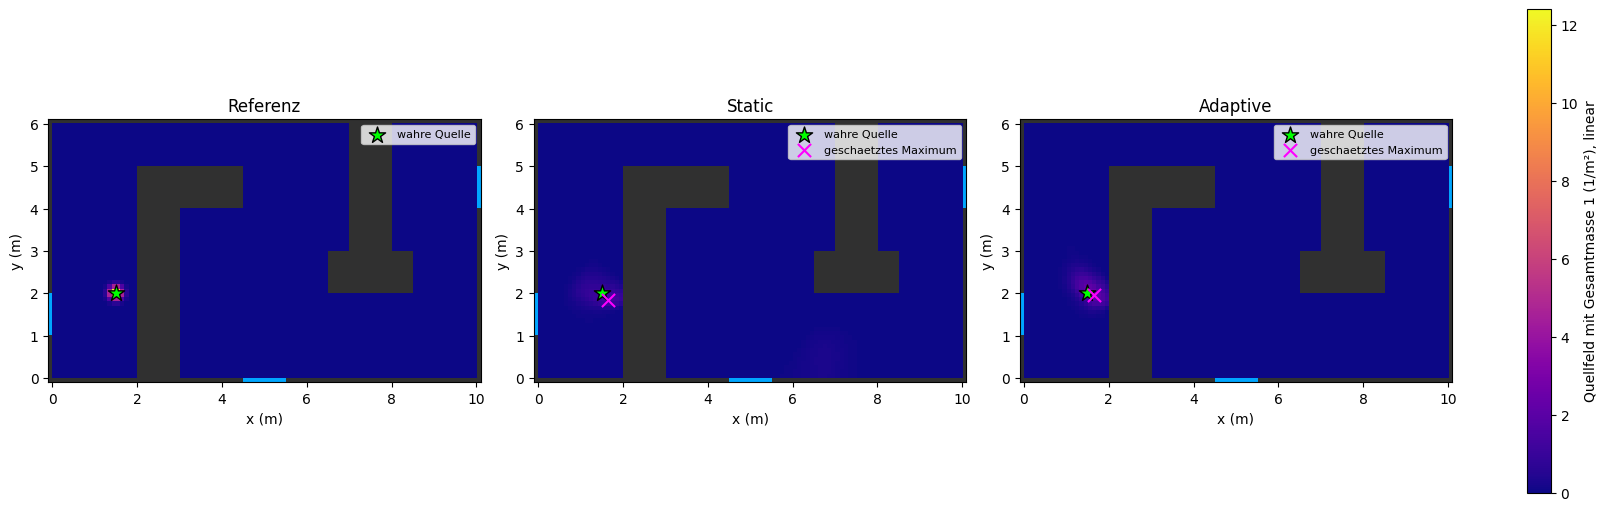

          position_error_m  point_w1_m  normalized_l2  source_mass   data_mse    pde_mse   wall_mse
method                                                                                             
Static             0.21213      1.8987         2.5333       1.1947 0.00029716 0.00093316 7.7399e-05
Adaptive           0.15811     0.34313         2.3316      0.85575 1.0559e-07  0.0052618  8.592e-07


In [50]:
source_fields = {"Referenz": reference_q}
final_metrics = []
for label, run in comparison_runs.items():
    q = np.asarray(run["estimator"].predict_source(candidate_points)).reshape(-1)
    source_fields[label] = q / (cell_area * q.sum())
    raw = unweighted_losses(run["history"])
    final_metrics.append({
        "method": label, **run["progress"].iloc[-1].to_dict(),
        "data_mse": raw["gas_data"][-1], "pde_mse": raw["ad"][-1],
        "wall_mse": raw["gas_wall"][-1],
    })

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
extent = [occupancy.lower_bound[0], occupancy.upper_bound[0],
          occupancy.lower_bound[1], occupancy.upper_bound[1]]
vmax = max(float(values.max()) for values in source_fields.values())
for ax, (label, values) in zip(axes, source_fields.items()):
    occupancy.plot(ax=ax, title=label)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    field = np.full(occupancy.free_mask.shape, np.nan)
    field[occupancy.free_mask] = values
    image = ax.imshow(field, origin="lower", extent=extent, cmap="plasma",
                      vmin=0, vmax=vmax,
                      interpolation="nearest", zorder=2)
    ax.scatter(*true_source, marker="*", s=150, color="lime", edgecolor="black",
               label="wahre Quelle", zorder=5)
    if label != "Referenz":
        ax.scatter(*candidate_points[np.argmax(values)], marker="x", s=90,
                   color="magenta", label="geschaetztes Maximum", zorder=6)
    ax.legend(fontsize=8)
fig.colorbar(image, ax=axes, label="Quellfeld mit Gesamtmasse 1 (1/m²), linear")
plt.show()

# Feldkarten sind normiert; source_mass zeigt die nicht normierte Quellstaerke.
summary = pd.DataFrame(final_metrics).set_index("method").drop(columns="step")
print(summary.to_string(float_format=lambda value: f"{value:.5g}"))

### Direkter Vergleich mit dem oberen Lauf

Hier werden die **nicht normierten Quellwerte** des oberen Laufs und der beiden
Vergleichslaeufe mit derselben **linearen** Farbskala dargestellt. Bei unveraenderten
Parametern und Messdaten soll die adaptive Wiederholung den oberen Lauf reproduzieren.
Die maximale numerische Abweichung wird darunter ausgegeben.


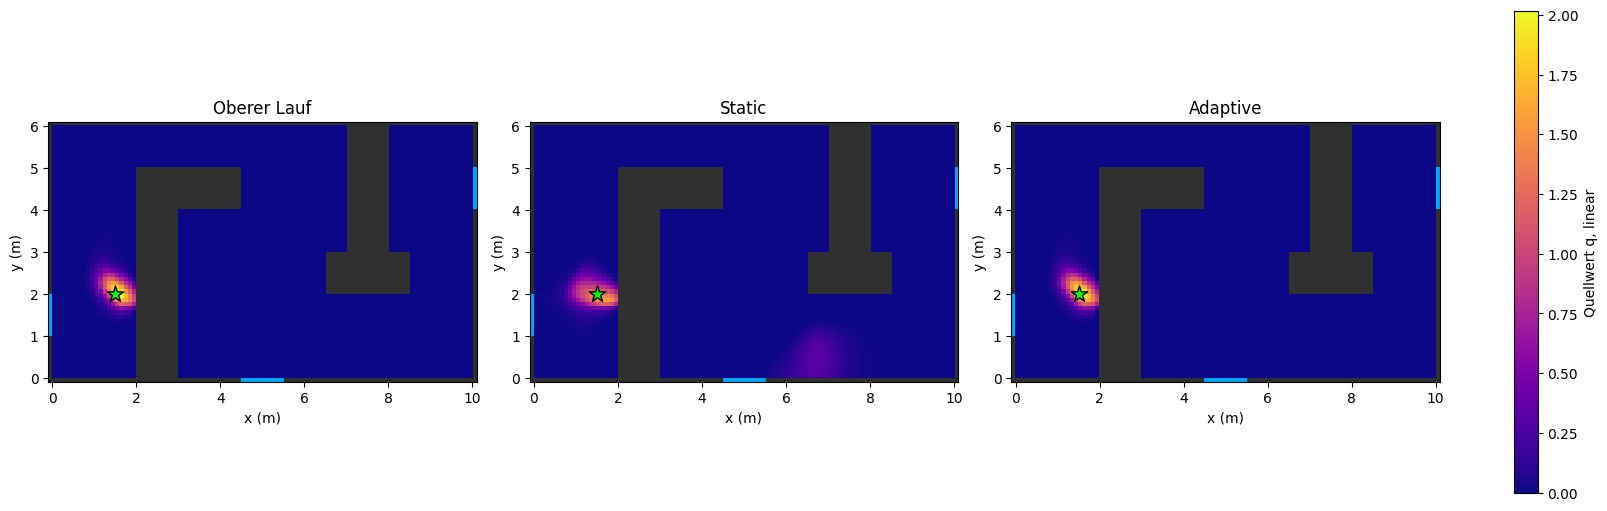

Max. |q oben - q adaptive Wiederholung|: 0.0


In [51]:
direct_fields = {
    "Oberer Lauf": np.asarray(localizer.predict_source(candidate_points)).reshape(-1),
    **{label: np.asarray(run["estimator"].predict_source(candidate_points)).reshape(-1)
       for label, run in comparison_runs.items()},
}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
vmax = max(float(values.max()) for values in direct_fields.values())
for ax, (label, values) in zip(axes, direct_fields.items()):
    occupancy.plot(ax=ax, title=label)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    field = np.full(occupancy.free_mask.shape, np.nan)
    field[occupancy.free_mask] = values
    image = ax.imshow(field, origin="lower", extent=extent, cmap="plasma",
                      vmin=0, vmax=vmax, interpolation="nearest", zorder=2)
    ax.scatter(*true_source, marker="*", s=150, color="lime", edgecolor="black", zorder=5)
fig.colorbar(image, ax=axes, label="Quellwert q, linear")
plt.show()
print("Max. |q oben - q adaptive Wiederholung|:",
      np.max(np.abs(direct_fields["Oberer Lauf"] - direct_fields["Adaptive"])))